# Hardening and Overshoot



## Modeling

In [ ]:
import xara

E = 100.0
nu = 0.3

Fy = 15.0

materials = {
    "Lubliner": xara.MultiaxialMaterial("GeneralizedJ2",
        E=E, 
        nu=nu, 
        Fy=Fy,
        Hiso=0.0, 
        Hkin=0.0,
        C=10, 
        # gamma=9.0,
        Fs=25.0,
        tol=1e-10,
        overstress=25.0, 
        transition=50
    ),

    "Mises": xara.MultiaxialMaterial("PlasticJ2",
        E=E, 
        nu=nu, 
        Fy=Fy,
        Hiso=0.0,
        C=10,
        gamma=9.0,
        Q=[10, 0], 
        b=[50, 0],
        Fs=25.0,
        tol=1e-10,
    ),

    "Mises-Montans": xara.MultiaxialMaterial(
        "MisesBoundingSurface", E=E, nu=nu, 
        Fy=1.0*Fy,
        Fs=1.5*Fy,
        Hy=10, #0.1*Ec,
        m=2,
        h=1.5*E, #0.1*G,
        H0=0
    ),
}

## Analysis

In [2]:
import numpy as np

# Loading histories: (time, value) pairs
shear = [(0,0), (1,1.2), (3,-1.2), (5,1.2), (6,0), (7,1.2), (9,-1.2), (11,1.2), (12,0), (13,1.2)]
axial = [(0,0), (5,0), (6,0.7), (7,0), (11,0), (12,0.7), (13,0)]

t_s, g_s = map(np.array, zip(*shear))
t_a, e_a = map(np.array, zip(*axial))

nstep = 500
times = np.linspace(0, max(np.max(t_s), np.max(t_a)), nstep)
gamma_xz = np.interp(times, t_s, g_s)
eps_zz   = np.interp(times, t_a, e_a)



In [3]:
def test_erasure(mat):
    tau, sig, gam, eps = [], [], [], []

    # Voigt order: [xx, yy, zz, xy, xz, yz]
    with mat as tmp:
        for i in range(nstep):
            strain = (0.0, 0.0, eps_zz[i], 0.0, gamma_xz[i], 0.0)
            try:
                stress = tmp.getStress(strain, commit=True)
            except:
                print(f"Error at step {i}: strain={strain}")
                break

            sig.append(stress[2])
            tau.append(stress[4])
            eps.append(strain[2])
            gam.append(strain[4])

    return tau, sig, gam, eps


{'name': 1, 'type': 'GeneralizedJ2', 'E': 100, 'nu': 0.3, 'Fy': 15, 'Fs': 25, 'Hiso': 0, 'Hkin': 10, 'delta': 50, 'rule': 'GP', 'density': 0}
{'name': 1, 'type': 'NonlinearJ2', 'E': 100, 'nu': 0.3, 'Fy': 15, 'Q': [10, 0], 'b': [50, 0], 'C': [10], 'gamma': [9], 'Hiso': 0, 'gtol': 1e-10, 'MaxIter': 15, 'density': 0}
{'name': 1, 'type': 'MisesBoundingSurface', 'E': 100, 'nu': 0.3, 'R': 18.3712, 'r': 12.2474, 'Hy': 10, 'h': 150, 'm': 2, 'H0': 0, 'memory': 0, 'gtol': 1e-10, 'MaxIter': 50, 'density': 0}


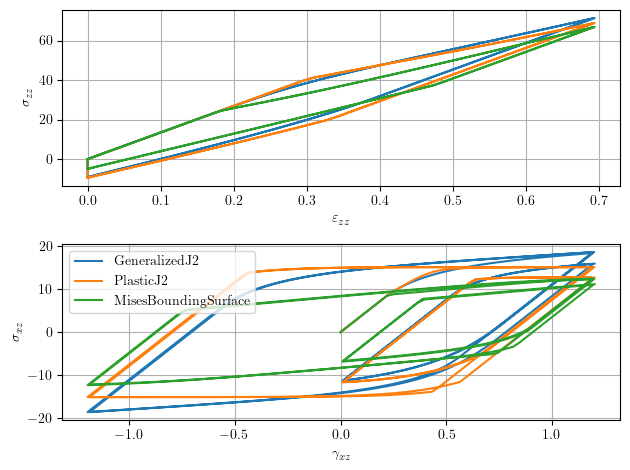

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 1)

for material in materials.values():
    print(material.asdict())
    tau, sig, gam, eps = test_erasure(material)
    ax[0].plot(eps, sig)
    ax[1].plot(gam, tau, label=material.type)


ax[1].set_ylabel(r'$\sigma_{xz}$')
ax[1].set_xlabel(r'$\gamma_{xz}$')
ax[0].set_ylabel(r'$\sigma_{zz}$')
ax[0].set_xlabel(r'$\varepsilon_{zz}$')
ax[1].legend()
ax[0].grid(True)
ax[1].grid(True)
plt.tight_layout()

## References

- Auricchio, F., and R.L. Taylor. 
  “Two Material Models for Cyclic Plasticity: Nonlinear Kinematic Hardening and Generalized Plasticity.” 
  International Journal of Plasticity 11, no. 1 (1995): 65–98. 
  [doi: 10.1016/0749-6419(94)00039-5](https://doi.org/10.1016/0749-6419(94)00039-5).
